# Perbandingan 3 File Hierarchical Clustering

Membandingkan Agglomerative (Average Linkage) dan Divisive (DIANA) dengan Euclidean, Manhattan, dan Cosine. Notebook ini membaca tabel evaluasi dan gambar asli yang tersimpan di tiga notebook model, tanpa menjalankan ulang model.

## 0. Setup

In [1]:
import json
import base64
import io
from pathlib import Path
from html.parser import HTMLParser
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

plt.rcParams['figure.dpi'] = 120
OUTPUT_DIR = Path('outputPerbandinganHierarchical')
OUTPUT_DIR.mkdir(exist_ok=True)

## 1. Menentukan Ketiga File Notebook

In [2]:
BASE_DIR = Path.cwd()
FILES = {
    'Euclidean': BASE_DIR / 'Hierarchical_Euclidian.ipynb',
    'Manhattan': BASE_DIR / 'Hierarchical_Manhattan.ipynb',
    'Cosine': BASE_DIR / 'Hierarchical_Cosine.ipynb',
}
for metric, path in FILES.items():
    if not path.is_file():
        raise FileNotFoundError(
            f'{metric}: {path} tidak ditemukan. Sesuaikan BASE_DIR/nama file pada bagian 1.'
        )
    print(f'{metric}: {path.name}')

Euclidean: Hierarchical_Euclidian.ipynb
Manhattan: Hierarchical_Manhattan.ipynb
Cosine: Hierarchical_Cosine.ipynb


## 2. Fungsi Membaca Output Notebook

Tabel HTML `df_eval` dibaca berdasarkan nama kolom dan nama metode, sehingga hasil Agglomerative tidak tertukar dengan Divisive. Kode sumber notebook model tidak dieksekusi. Jika output belum disimpan, jalankan Run All dan Save pada notebook model.

In [3]:
def as_text(value):
    return ''.join(value) if isinstance(value, list) else str(value)

class TableReader(HTMLParser):
    def __init__(self):
        super().__init__()
        self.rows = []
        self.row = None
        self.cell = None
    def handle_starttag(self, tag, attrs):
        if tag == 'tr':
            self.row = []
        elif tag in ('th', 'td') and self.row is not None:
            self.cell = []
    def handle_data(self, data):
        if self.cell is not None:
            self.cell.append(data)
    def handle_endtag(self, tag):
        if tag in ('th', 'td') and self.cell is not None:
            self.row.append(''.join(self.cell).strip())
            self.cell = None
        elif tag == 'tr' and self.row is not None:
            self.rows.append(self.row)
            self.row = None

def load_notebook(path):
    with path.open(encoding='utf-8') as handle:
        return json.load(handle)

REQUIRED = ['Metode', 'Metrik_Jarak', 'Linkage', 'Jumlah_Cluster',
            'Waktu_Detik', 'Peak_Memory_MB', 'Silhouette', 'DBI', 'Calinski_Harabasz']
NUMERIC = REQUIRED[3:]

def extract_metrics(nb, path, expected_metric):
    for cell in nb['cells']:
        if 'df_eval =' not in as_text(cell.get('source', [])):
            continue
        for output in reversed(cell.get('outputs', [])):
            html = output.get('data', {}).get('text/html')
            if not html:
                continue
            parser = TableReader()
            parser.feed(as_text(html))
            if not parser.rows:
                continue
            headers = parser.rows[0]
            if not set(REQUIRED).issubset(headers):
                continue
            rows = [dict(zip(headers, row)) for row in parser.rows[1:]
                    if len(row) == len(headers)]
            frame = pd.DataFrame(rows)[REQUIRED].copy()
            if len(frame) != 2 or set(frame['Metode']) != {'Agglomerative', 'Divisive (DIANA)'}:
                raise ValueError(f'{path.name}: tabel harus berisi tepat dua metode.')
            if not frame['Metrik_Jarak'].eq(expected_metric).all():
                raise ValueError(f'{path.name}: metrik tabel tidak sesuai {expected_metric}.')
            for column in NUMERIC:
                frame[column] = pd.to_numeric(frame[column], errors='raise')
            if not np.isfinite(frame[NUMERIC].to_numpy(dtype=float)).all():
                raise ValueError(f'{path.name}: tabel berisi nilai non-finite.')
            frame['Jumlah_Cluster'] = frame['Jumlah_Cluster'].astype(int)
            frame['File_Sumber'] = path.name
            return frame
    raise ValueError(
        f'{path.name}: output tabel df_eval tidak ditemukan. Jalankan bagian evaluasi '
        'dan simpan notebook model, lalu ulangi notebook analisis.'
    )

def extract_image(nb, path, kind):
    for cell in nb['cells']:
        source = as_text(cell.get('source', []))
        matches = ('pca_comparison_' in source) if kind == 'pca' else ('dendrogram_agg_' in source)
        if not matches:
            continue
        for output in reversed(cell.get('outputs', [])):
            encoded = output.get('data', {}).get('image/png')
            if encoded:
                raw = base64.b64decode(as_text(encoded))
                with Image.open(io.BytesIO(raw)) as img:
                    return img.convert('RGB').copy()
    raise ValueError(f'{path.name}: gambar {kind} belum tersimpan. Jalankan visualisasi dan Save notebook.')

## 3. Mengambil Hasil Ketiga Metrik

In [4]:
notebooks = {metric: load_notebook(path) for metric, path in FILES.items()}
comparison = pd.concat([
    extract_metrics(notebooks[metric], path, metric)
    for metric, path in FILES.items()
], ignore_index=True)
comparison['Kombinasi'] = comparison['Metode'] + ' / ' + comparison['Metrik_Jarak']
display(comparison)

,Metode,Metrik_Jarak,Linkage,Jumlah_Cluster,Waktu_Detik,Peak_Memory_MB,Silhouette,DBI,Calinski_Harabasz,File_Sumber,Kombinasi
0,Agglomerative,Euclidean,Average,3,0.6587,11.92,0.0966,1.3654,401.0620,Hierarchical_Euclidian.ipynb,Agglomerative / Euclidean
1,Divisive (DIANA),Euclidean,-,3,1.0700,382.32,0.0610,3.4608,632.2916,Hierarchical_Euclidian.ipynb,Divisive (DIANA) / Euclidean
2,Agglomerative,Manhattan,Average,3,0.4944,11.92,0.1672,2.5412,735.0342,Hierarchical_Manhattan.ipynb,Agglomerative / Manhattan
3,Divisive (DIANA),Manhattan,-,3,0.7987,382.17,0.1587,2.6090,705.9105,Hierarchical_Manhattan.ipynb,Divisive (DIANA) / Manhattan
4,Agglomerative,Cosine,Average,3,0.5978,11.92,0.1388,3.7722,487.1000,Hierarchical_Cosine.ipynb,Agglomerative / Cosine
5,Divisive (DIANA),Cosine,-,3,0.9894,382.17,0.1574,3.3787,596.5761,Hierarchical_Cosine.ipynb,Divisive (DIANA) / Cosine


### 3.1 Pemeriksaan Jumlah Klaster

`Jumlah_Cluster` pada tabel sumber berasal dari `k_target`, sehingga dibaca sebagai jumlah yang ditetapkan/dilaporkan, bukan verifikasi ulang jumlah label aktual.

In [5]:
if comparison['Jumlah_Cluster'].nunique() == 1:
    print(f"Keenam konfigurasi melaporkan k = {comparison['Jumlah_Cluster'].iloc[0]}.")
else:
    print('Jumlah klaster yang dilaporkan berbeda; pertimbangkan perbedaan ini saat membaca skor.')
display(comparison[['Metode', 'Metrik_Jarak', 'Jumlah_Cluster']])

Keenam konfigurasi melaporkan k = 3.


,Metode,Metrik_Jarak,Jumlah_Cluster
0,Agglomerative,Euclidean,3
1,Divisive (DIANA),Euclidean,3
2,Agglomerative,Manhattan,3
3,Divisive (DIANA),Manhattan,3
4,Agglomerative,Cosine,3
5,Divisive (DIANA),Cosine,3


## 4. Diagram Perbandingan Kuantitatif

Setiap grafik membandingkan tiga metrik dengan dua batang per metrik. Silhouette memakai jarak berbeda antar metrik, sehingga tidak menjadi dasar tunggal pemilihan metrik terbaik. DBI dan Calinski-Harabasz dihitung pada fitur standar dengan geometri Euclidean di seluruh notebook.

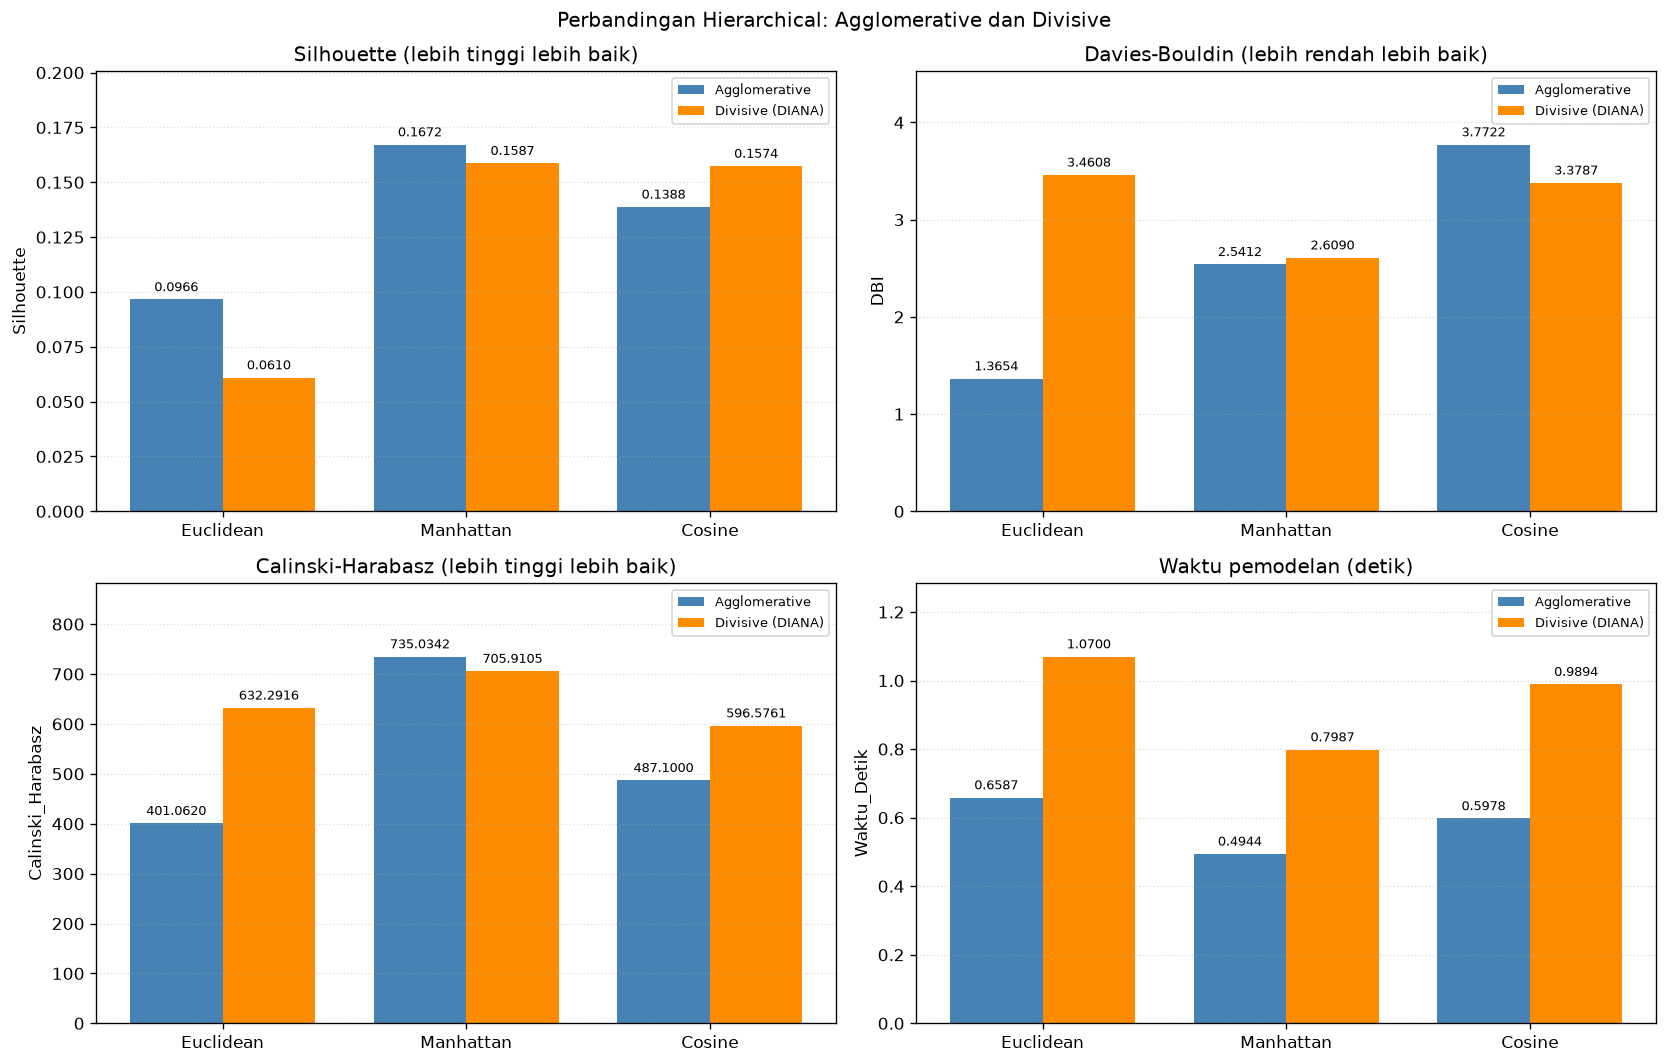

In [6]:
METRIC_ORDER = ['Euclidean', 'Manhattan', 'Cosine']
METHOD_ORDER = ['Agglomerative', 'Divisive (DIANA)']

def grouped_bars(ax, column, title):
    table = comparison.pivot(index='Metrik_Jarak', columns='Metode', values=column)
    table = table.reindex(index=METRIC_ORDER, columns=METHOD_ORDER)
    positions = np.arange(len(table))
    for offset, method, color in zip([-0.19, 0.19], METHOD_ORDER, ['steelblue', 'darkorange']):
        bars = ax.bar(positions + offset, table[method], width=0.38, label=method, color=color)
        ax.bar_label(bars, fmt='%.4f', padding=3, fontsize=8)
    ax.set_xticks(positions, table.index)
    ax.set_title(title)
    ax.set_ylabel(column)
    ax.grid(axis='y', linestyle=':', alpha=0.4)
    ax.margins(y=0.2)
    ax.legend(fontsize=8)

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, column, title in zip(axes.flat,
    ['Silhouette', 'DBI', 'Calinski_Harabasz', 'Waktu_Detik'],
    ['Silhouette (lebih tinggi lebih baik)', 'Davies-Bouldin (lebih rendah lebih baik)',
     'Calinski-Harabasz (lebih tinggi lebih baik)', 'Waktu pemodelan (detik)']):
    grouped_bars(ax, column, title)
fig.suptitle('Perbandingan Hierarchical: Agglomerative dan Divisive')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'perbandingan_metrik_hierarchical.png', dpi=200, bbox_inches='tight')
plt.show()

## 5. Mengambil Gambar PCA dan Dendrogram Asli

Gambar dibaca langsung dari output tersimpan; tidak ada perhitungan PCA atau dendrogram ulang.

In [7]:
pca_images = {metric: extract_image(notebooks[metric], FILES[metric], 'pca') for metric in METRIC_ORDER}
dendrogram_images = {metric: extract_image(notebooks[metric], FILES[metric], 'dendrogram') for metric in METRIC_ORDER}
print('Gambar PCA dan dendrogram ketiga notebook berhasil dibaca.')

Gambar PCA dan dendrogram ketiga notebook berhasil dibaca.


## 6. Visualisasi Perbandingan

Setiap gambar PCA asli berisi dua panel: Agglomerative dan Divisive. Tiga gambar disusun vertikal agar label tetap terbaca. Nomor/warna klaster antar metode bukan identitas kelompok yang sama.

### 6.1 Perbandingan PCA

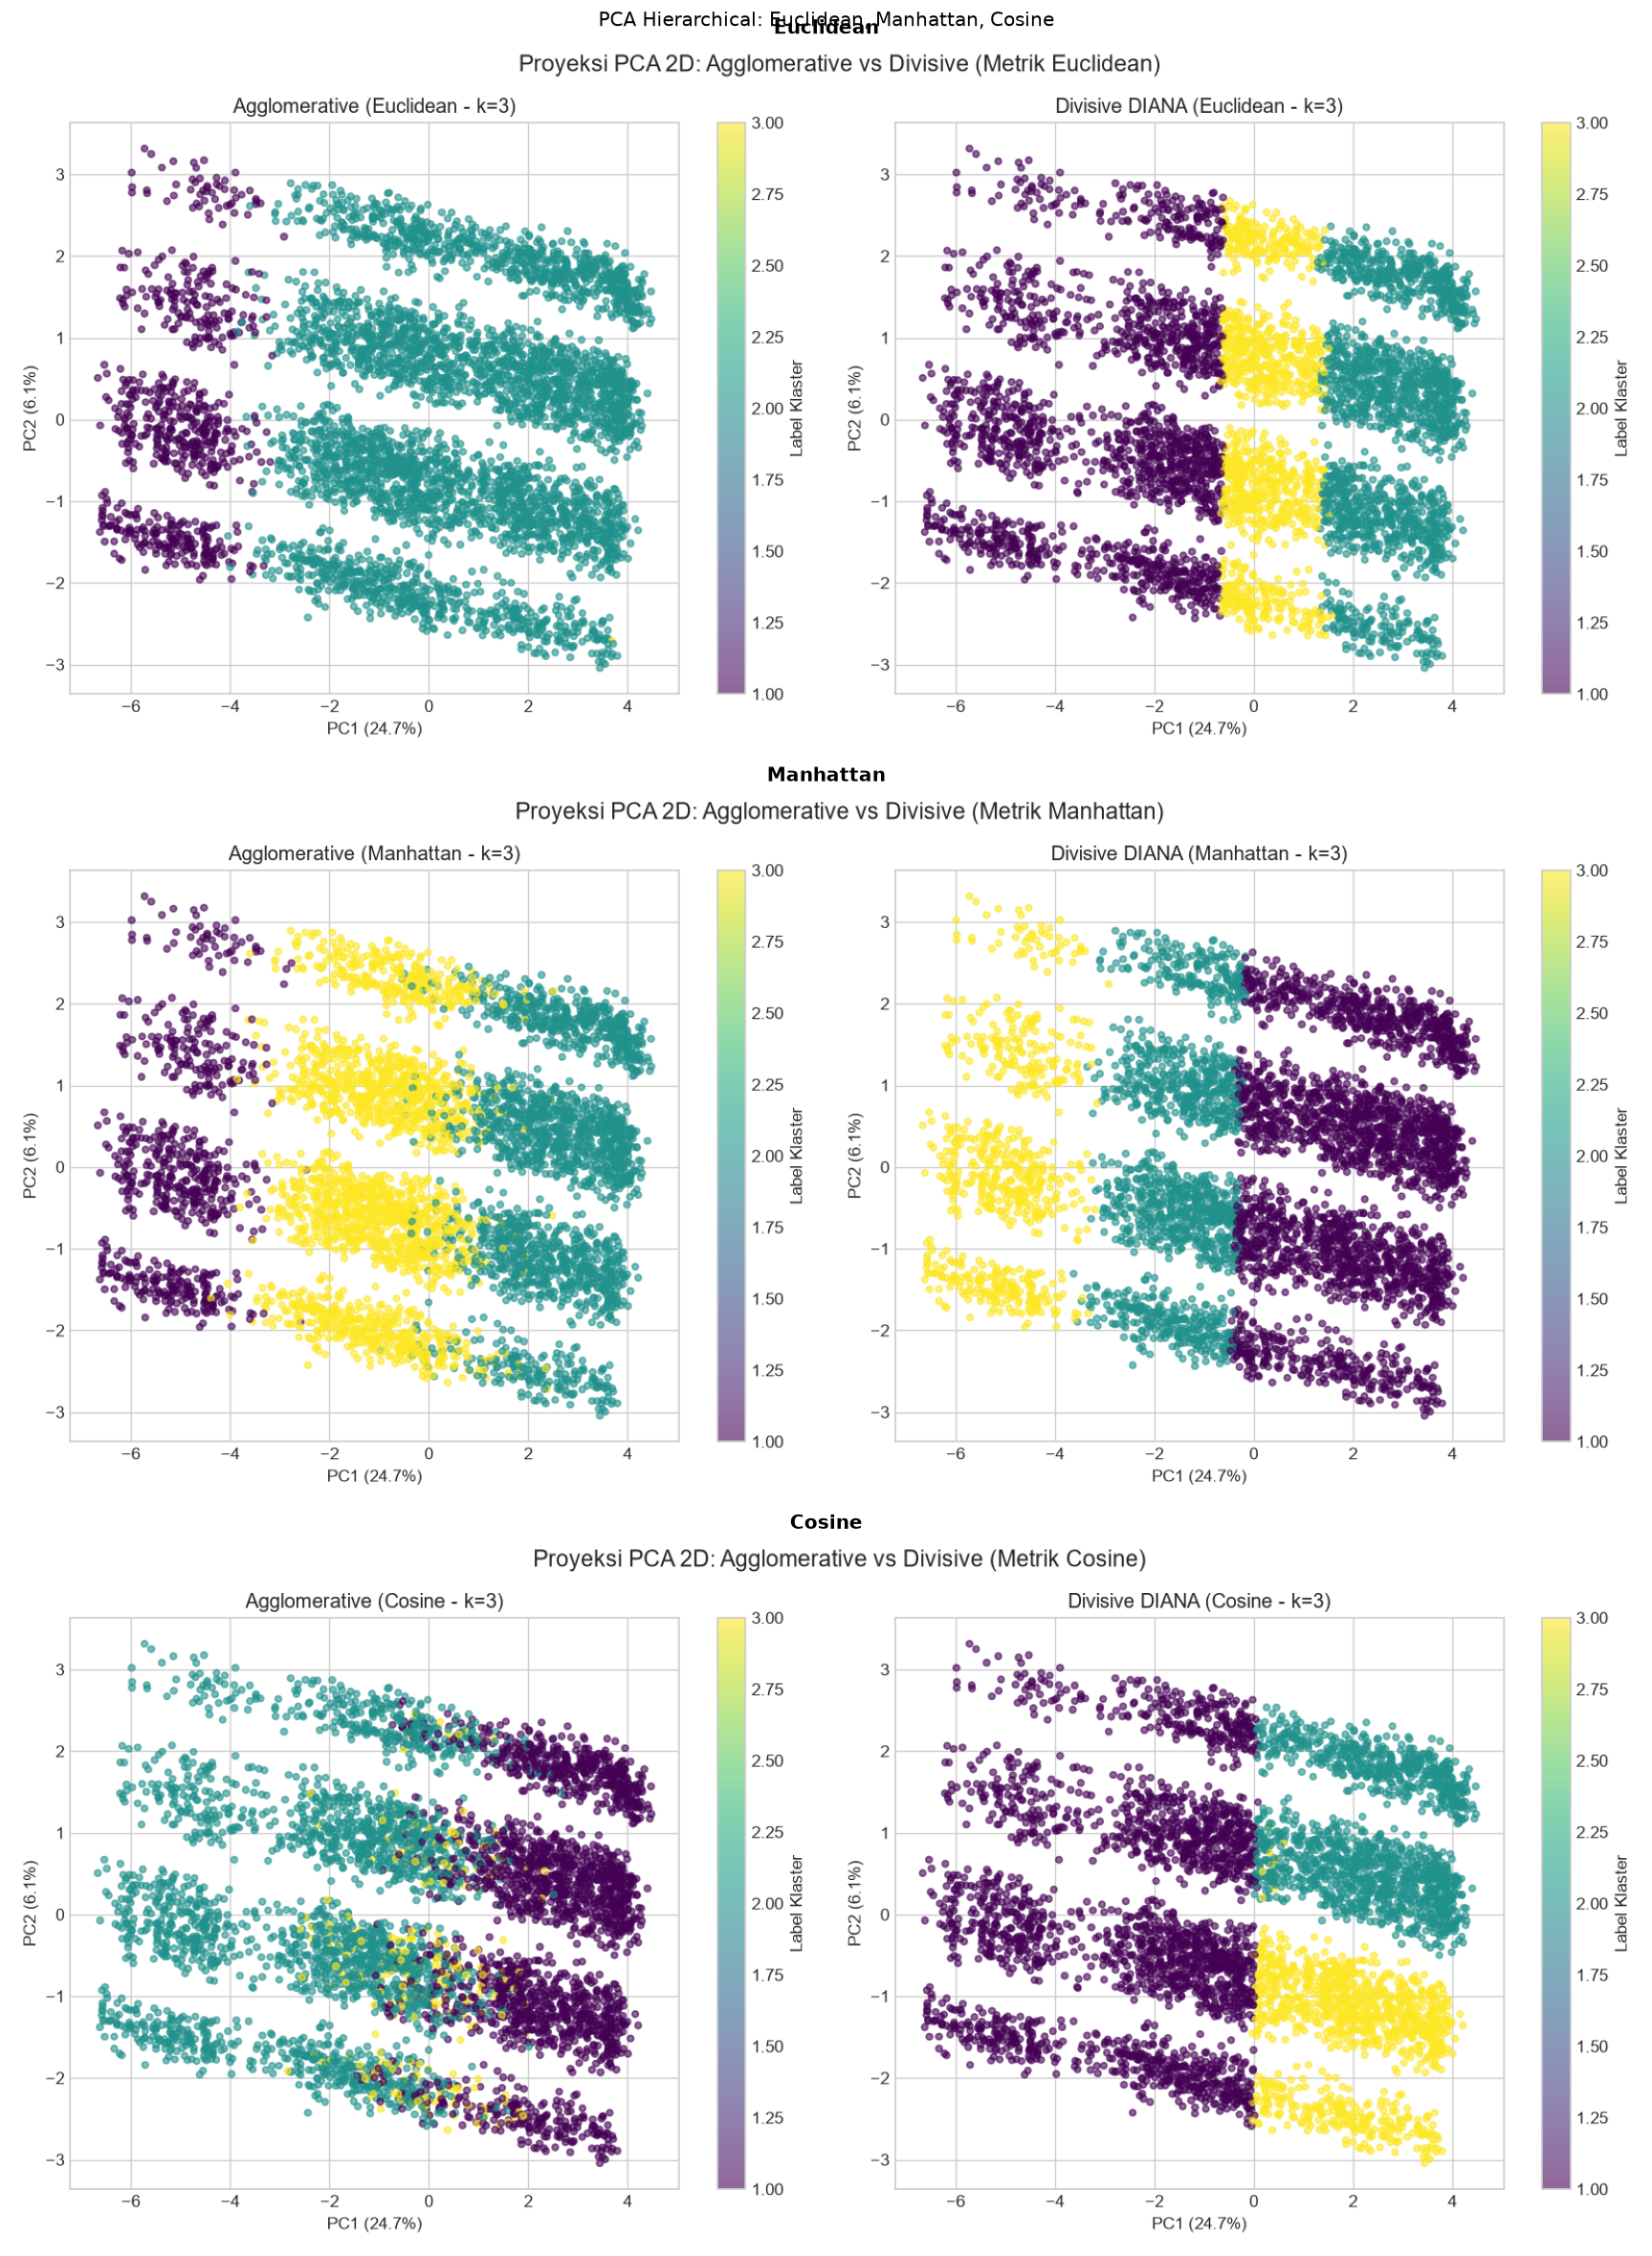

In [8]:
fig, axes = plt.subplots(3, 1, figsize=(16, 20))
for ax, metric in zip(axes, METRIC_ORDER):
    ax.imshow(pca_images[metric])
    ax.set_title(metric, fontweight='bold')
    ax.axis('off')
fig.suptitle('PCA Hierarchical: Euclidean, Manhattan, Cosine')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'perbandingan_pca_hierarchical.png', dpi=150, bbox_inches='tight')
plt.show()

### 6.2 Perbandingan Dendrogram Agglomerative

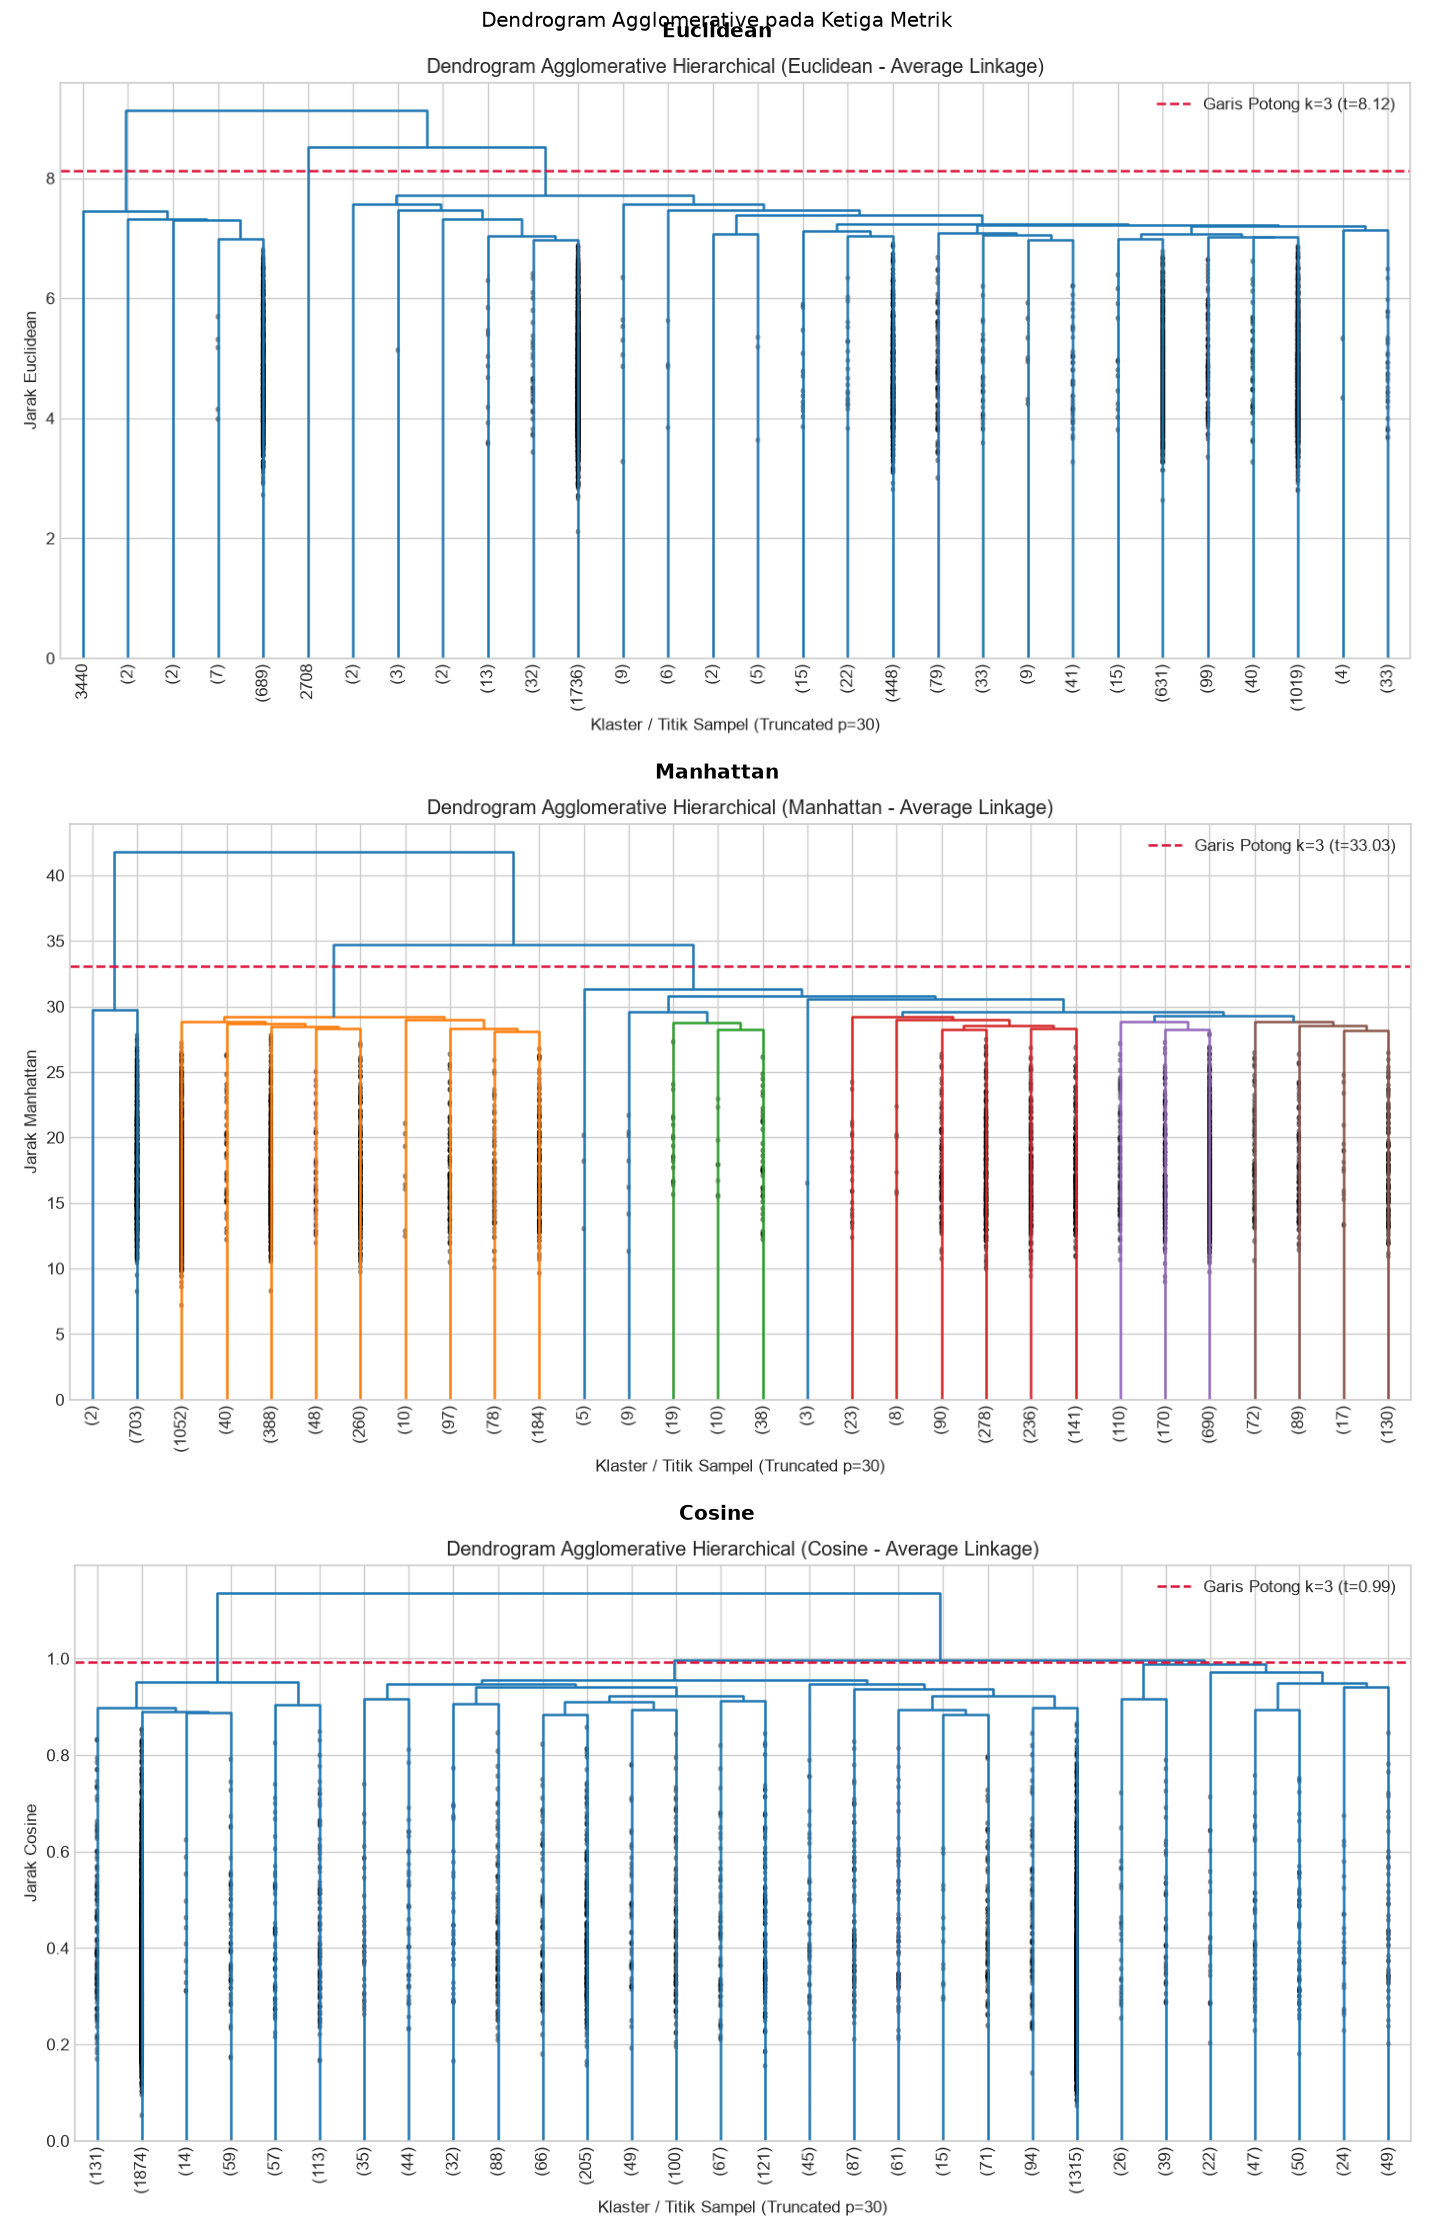

In [9]:
fig, axes = plt.subplots(3, 1, figsize=(14, 19))
for ax, metric in zip(axes, METRIC_ORDER):
    ax.imshow(dendrogram_images[metric])
    ax.set_title(metric, fontweight='bold')
    ax.axis('off')
fig.suptitle('Dendrogram Agglomerative pada Ketiga Metrik')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'perbandingan_dendrogram_hierarchical.png', dpi=150, bbox_inches='tight')
plt.show()

## 7. Perbandingan Efisiensi Tambahan

Jumlah iterasi K-Means tidak tersedia untuk model hierarchical ini, sehingga tidak dibandingkan. Memori adalah peak traced memory selama pemodelan, bukan total RAM notebook. Waktu model tidak mencakup pembuatan matriks jarak maupun evaluasi.

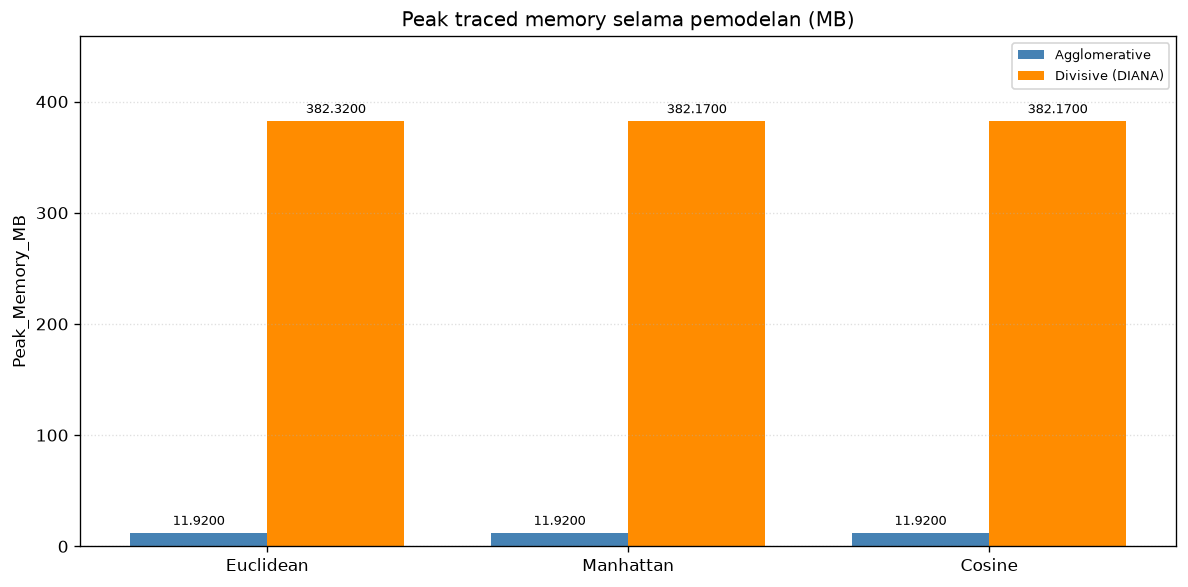

In [10]:
fig, ax = plt.subplots(figsize=(10, 5))
grouped_bars(ax, 'Peak_Memory_MB', 'Peak traced memory selama pemodelan (MB)')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'perbandingan_memori_hierarchical.png', dpi=200, bbox_inches='tight')
plt.show()

## 8. Tabel Hasil Akhir

In [11]:
for method in METHOD_ORDER:
    print(method)
    display(comparison.loc[comparison['Metode'].eq(method)].drop(columns='Kombinasi'))

Agglomerative


,Metode,Metrik_Jarak,Linkage,Jumlah_Cluster,Waktu_Detik,Peak_Memory_MB,Silhouette,DBI,Calinski_Harabasz,File_Sumber
0,Agglomerative,Euclidean,Average,3,0.6587,11.92,0.0966,1.3654,401.0620,Hierarchical_Euclidian.ipynb
2,Agglomerative,Manhattan,Average,3,0.4944,11.92,0.1672,2.5412,735.0342,Hierarchical_Manhattan.ipynb
4,Agglomerative,Cosine,Average,3,0.5978,11.92,0.1388,3.7722,487.1000,Hierarchical_Cosine.ipynb


Divisive (DIANA)


,Metode,Metrik_Jarak,Linkage,Jumlah_Cluster,Waktu_Detik,Peak_Memory_MB,Silhouette,DBI,Calinski_Harabasz,File_Sumber
1,Divisive (DIANA),Euclidean,-,3,1.0700,382.32,0.0610,3.4608,632.2916,Hierarchical_Euclidian.ipynb
3,Divisive (DIANA),Manhattan,-,3,0.7987,382.17,0.1587,2.6090,705.9105,Hierarchical_Manhattan.ipynb
5,Divisive (DIANA),Cosine,-,3,0.9894,382.17,0.1574,3.3787,596.5761,Hierarchical_Cosine.ipynb


### 8.1 Panduan Analisis

Bandingkan Agglomerative dan Divisive dalam metrik jarak yang sama terlebih dahulu. Lalu bandingkan pola skor dan efisiensi antar metrik. Skor yang saling bertentangan perlu dibahas, bukan dirata-ratakan menjadi satu peringkat. Waktu dipengaruhi perangkat dan kondisi eksekusi. Nilai dibaca dari tabel sumber yang telah dibulatkan. Tidak ada hasil yang dihitung atau ditebak ketika output sumber hilang.

## 9. Ekspor Hasil Perbandingan

In [12]:
comparison.to_csv(OUTPUT_DIR / 'perbandingan_hierarchical.csv', index=False)
try:
    comparison.to_excel(OUTPUT_DIR / 'perbandingan_hierarchical.xlsx', index=False)
except ImportError:
    print('CSV tersimpan. Untuk ekspor Excel, pasang openpyxl pada kernel VS Code: %pip install openpyxl')
print(f'Hasil disimpan ke: {OUTPUT_DIR.resolve()}')
for path in sorted(OUTPUT_DIR.glob('*')):
    print('-', path.name)

Hasil disimpan ke: D:\My Files\File Penting\MachineLearning\Pertemuan_7\UTS\outputPerbandinganHierarchical
- perbandingan_dendrogram_hierarchical.png
- perbandingan_hierarchical.csv
- perbandingan_hierarchical.xlsx
- perbandingan_memori_hierarchical.png
- perbandingan_metrik_hierarchical.png
- perbandingan_pca_hierarchical.png
